<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%209/DS_Practice_SemiSupervised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%20X/DS_Practice_SemiSupervised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Data Science
## Practice Session: Semi-Supervised Learning
**Eötvös Loránd University (ELTE) · Faculty of Informatics**

---
**Instructor:** Arafat Md Easin  
**Goal:** By the end of this session you will be able to:
- Explain **why semi-supervised learning exists** and the assumptions it relies on
- Simulate a realistic setting with **a few labels and many unlabeled samples**
- Apply **self-training, Label Propagation / Label Spreading, and cluster-then-label**
- Measure how accuracy changes with the **number of labels** and the **confidence threshold**
- Recognise **when unlabeled data does not help** and how to evaluate fairly

> **Tip:** Run each cell with `Shift + Enter` and read the comments carefully before moving on.  
> **Key principle:** Unlabeled data is only useful if its structure tells you something about the labels. Always compare against a supervised baseline trained on the same few labels, and evaluate on a held-out labeled test set.

---

## Part 0: Setup & Datasets

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_digits, load_wine, make_moons, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.semi_supervised import SelfTrainingClassifier, LabelSpreading
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# ── Reproducible randomness ───────────────────────────────────────────
RNG = np.random.default_rng(seed=42)

# ── Plot style ────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"]     = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print("Setup complete.")

Setup complete.


In [ ]:
# ── Load datasets ─────────────────────────────────────────────────────
# We use two classic sklearn datasets:
#   digits - 1,797 handwritten digit images (8x8 pixels = 64 features), 10 classes  (demos)
#   wine   - 13 chemical features, 3 cultivars                                       (exercises)
#
# In this notebook we PRETEND most labels are missing. Because we secretly know all labels,
# we can measure honestly how much the unlabeled data helped.

# Digits dataset (pixel values 0-16, rescaled to 0-1)
digits = load_digits()
X_dg = digits.data / 16.0
y_dg = digits.target

# Wine dataset
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
y_wine = pd.Series(wine.target, name="cultivar")

print("=== Digits ===")
print(f"  Samples: {X_dg.shape[0]},  Features: {X_dg.shape[1]},  Classes: {len(np.unique(y_dg))}")
print()
print("=== Wine ===")
print(f"  Samples: {X_wine.shape[0]},  Features: {X_wine.shape[1]}")
print(f"  Classes: {dict(zip(map(str, wine.target_names), map(int, np.bincount(y_wine))))}")

=== Digits ===
  Samples: 1797,  Features: 64,  Classes: 10

=== Wine ===
  Samples: 178,  Features: 13
  Classes: {'class_0': 59, 'class_1': 71, 'class_2': 48}


---
## Part 1: Why Semi-Supervised Learning?

In practice **labels are expensive** (a doctor must diagnose, an expert must annotate) while **unlabeled data is cheap** (images, text, sensor logs).

| Setting | Labeled data | Unlabeled data | Goal |
|---|---|---|---|
| **Supervised** | Plenty | Ignored | Predict labels |
| **Unsupervised** | None | All | Find structure |
| **Semi-supervised** | **A few** | **Many** | Predict labels, using the structure of the unlabeled data to do better than supervised alone |

**Why can unlabeled data help at all?** Only if the data distribution carries information about the labels. Three standard assumptions:

| Assumption | Meaning | Method that exploits it |
|---|---|---|
| **Smoothness** | Nearby points tend to share a label | Label Propagation / Spreading |
| **Cluster** | Points in the same cluster tend to share a label | Cluster-then-label |
| **Low-density separation** | Decision boundaries should pass through sparse regions | Self-training with a good base model |

> **Sklearn convention:** unlabeled samples are marked with the label **`-1`**.  
> **Transductive vs inductive:** *transductive* means predicting labels for the specific unlabeled points you were given; *inductive* means the fitted model also generalises to **new** points. We report both.

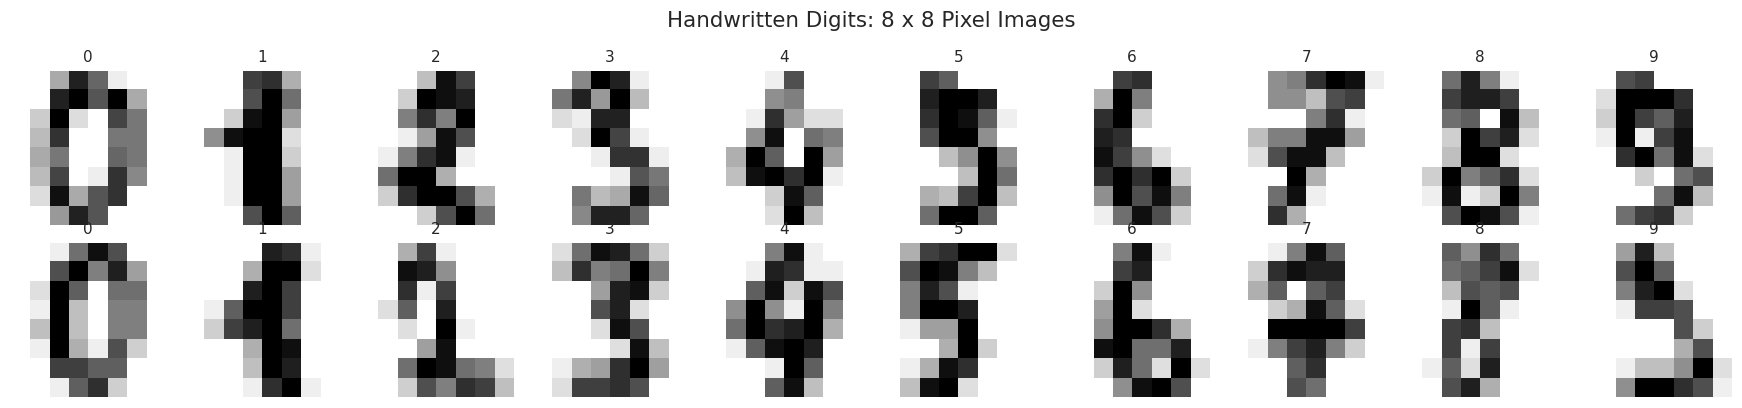

64 pixel features per image. Many digits look alike (3, 5, 8), which is where labels matter most.


In [ ]:
# ── 1.1  A look at the data ──────────────────────────────────────────

fig, axes = plt.subplots(2, 10, figsize=(16, 3.8))
fig.suptitle("Handwritten Digits: 8 x 8 Pixel Images", fontsize=14)
for i, ax in enumerate(axes.ravel()):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(f"{y_dg[i]}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

print("64 pixel features per image. Many digits look alike (3, 5, 8), which is where labels matter most.")

Train set: 1257 images   Test set: 540 images (labels kept for evaluation only)
Labeled:   50 (4.0%)
Unlabeled: 1207 (96.0%)


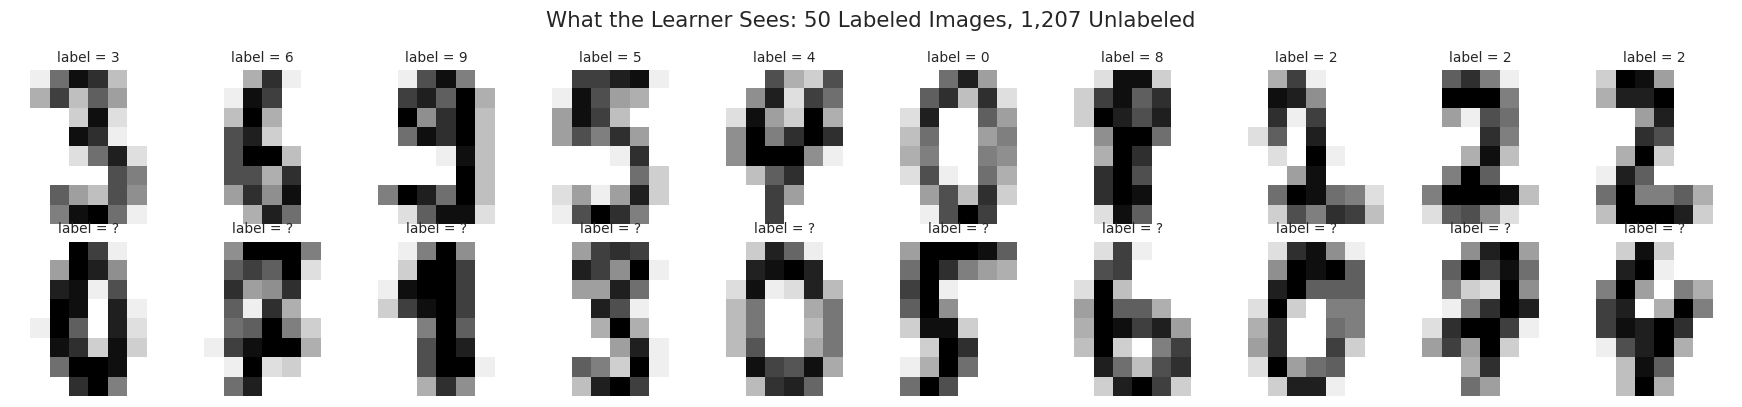

In [ ]:
# ── 1.2  Simulate scarce labels ──────────────────────────────────────
# 1) Hold out a TEST set that keeps its true labels. It is used only to measure accuracy.
# 2) In the TRAIN set, hide almost all labels by setting them to -1.

X_train, X_test, y_train, y_test = train_test_split(
    X_dg, y_dg, test_size=0.3, stratify=y_dg, random_state=42)

def make_semi_labels(y, n_labeled, seed=42):
    """Keep n_labeled labels (stratified); mark all others as -1. Returns (y_semi, labeled_idx)."""
    y   = np.asarray(y)
    idx = np.arange(len(y))
    lab_idx, _ = train_test_split(idx, train_size=n_labeled, stratify=y, random_state=seed)
    y_semi = np.full(len(y), -1)
    y_semi[lab_idx] = y[lab_idx]
    return y_semi, lab_idx

y_semi, lab_idx = make_semi_labels(y_train, n_labeled=50, seed=42)
unl_idx = np.where(y_semi == -1)[0]

print(f"Train set: {len(y_train)} images   Test set: {len(y_test)} images (labels kept for evaluation only)")
print(f"Labeled:   {len(lab_idx)} ({len(lab_idx) / len(y_train) * 100:.1f}%)")
print(f"Unlabeled: {len(unl_idx)} ({len(unl_idx) / len(y_train) * 100:.1f}%)")

fig, axes = plt.subplots(2, 10, figsize=(16, 3.8))
fig.suptitle("What the Learner Sees: 50 Labeled Images, 1,207 Unlabeled", fontsize=14)
for j in range(10):
    axes[0, j].imshow(X_train[lab_idx[j]].reshape(8, 8), cmap="gray_r")
    axes[0, j].set_title(f"label = {y_train[lab_idx[j]]}", fontsize=9)
    axes[1, j].imshow(X_train[unl_idx[j]].reshape(8, 8), cmap="gray_r")
    axes[1, j].set_title("label = ?", fontsize=9)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout()
plt.show()

---
## Part 2: The Baselines: What Are We Trying to Beat?

Every semi-supervised result must be compared with two supervised reference points:

| Baseline | Trained on | Meaning |
|---|---|---|
| **Lower bound** | Only the few labeled samples | What you get if you throw the unlabeled data away |
| **Upper bound** | All training labels | What you would get if labelling were free |

Semi-supervised learning is successful if it lands **between** them, ideally close to the upper bound.

> **Fairness rule:** the supervised baseline must use the **same labeled samples** as the semi-supervised method, otherwise you are measuring luck in which samples were labeled.

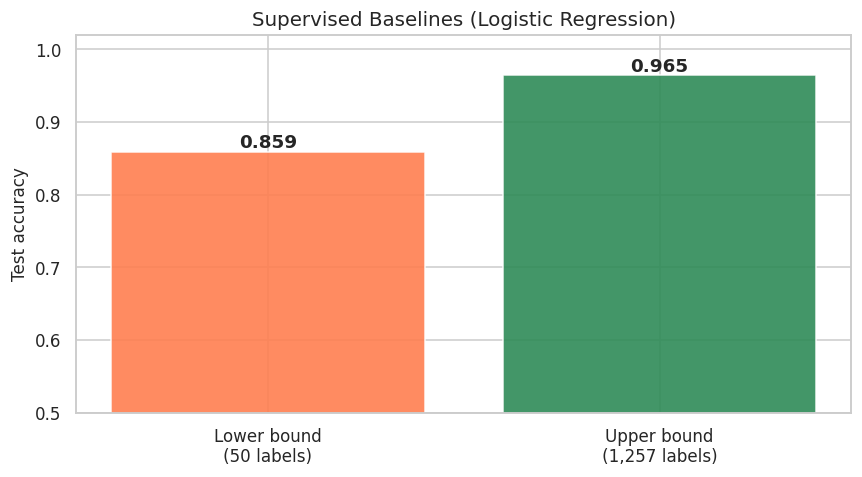

The gap to close: 0.106 accuracy points.
Semi-supervised methods try to recover part of this gap using the 1,207 unlabeled images.


In [ ]:
# ── 2.1  Lower and upper bounds ──────────────────────────────────────
# We use Logistic Regression with C=10 (weaker regularisation than the default).
# This makes its predicted probabilities more confident, which matters for self-training in Part 3.

def base_clf(C=10):
    return LogisticRegression(C=C, max_iter=3000)

lower = base_clf().fit(X_train[lab_idx], y_train[lab_idx])
upper = base_clf().fit(X_train, y_train)

acc_lower = accuracy_score(y_test, lower.predict(X_test))
acc_upper = accuracy_score(y_test, upper.predict(X_test))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(["Lower bound\n(50 labels)", "Upper bound\n(1,257 labels)"], [acc_lower, acc_upper],
       color=["coral", "seagreen"], edgecolor="white", alpha=0.9)
for i, v in enumerate([acc_lower, acc_upper]):
    ax.text(i, v + 0.005, f"{v:.3f}", ha="center", fontweight="bold")
ax.set_ylim(0.5, 1.02)
ax.set_ylabel("Test accuracy")
ax.set_title("Supervised Baselines (Logistic Regression)")
plt.tight_layout()
plt.show()

print(f"The gap to close: {acc_upper - acc_lower:.3f} accuracy points.")
print("Semi-supervised methods try to recover part of this gap using the 1,207 unlabeled images.")

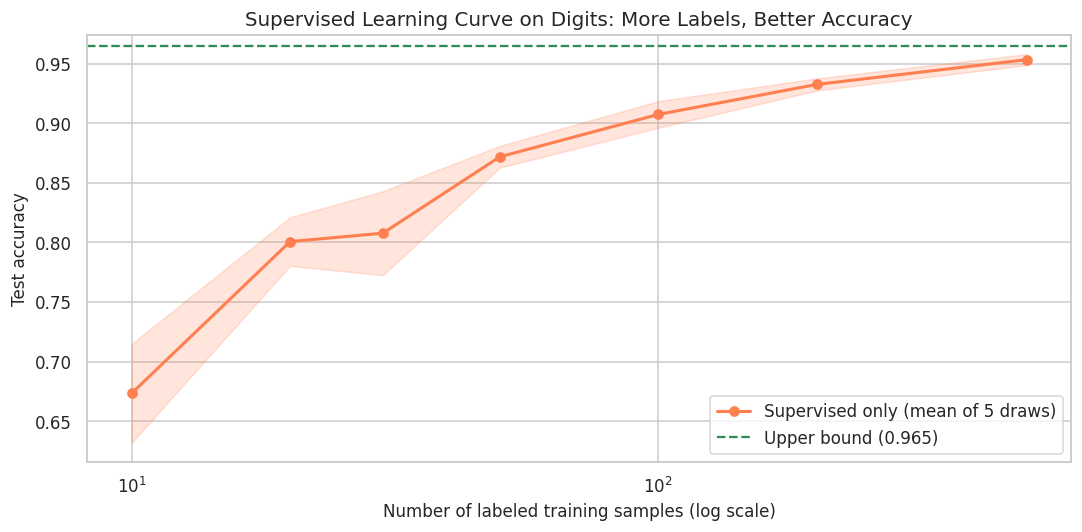

10 labels: 0.673    50 labels: 0.872    500 labels: 0.953
The steep part of this curve (few labels) is exactly where semi-supervised learning has the most to offer.


In [ ]:
# ── 2.2  Supervised learning curve: accuracy vs number of labels ─────
# Average over 5 random draws of which samples are labeled, to avoid relying on one lucky draw.

n_grid = [10, 20, 30, 50, 100, 200, 500]
n_seeds = 5

sup_curve = {}
for n in n_grid:
    accs = []
    for seed in range(n_seeds):
        _, li = make_semi_labels(y_train, n, seed)
        accs.append(accuracy_score(y_test, base_clf().fit(X_train[li], y_train[li]).predict(X_test)))
    sup_curve[n] = (np.mean(accs), np.std(accs))

fig, ax = plt.subplots(figsize=(10, 5))
means = np.array([sup_curve[n][0] for n in n_grid])
stds  = np.array([sup_curve[n][1] for n in n_grid])
ax.plot(n_grid, means, "o-", color="coral", linewidth=2, label="Supervised only (mean of 5 draws)")
ax.fill_between(n_grid, means - stds, means + stds, color="coral", alpha=0.2)
ax.axhline(acc_upper, color="seagreen", linestyle="--", linewidth=1.5, label=f"Upper bound ({acc_upper:.3f})")
ax.set_xscale("log")
ax.set_xlabel("Number of labeled training samples (log scale)")
ax.set_ylabel("Test accuracy")
ax.set_title("Supervised Learning Curve on Digits: More Labels, Better Accuracy")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"10 labels: {sup_curve[10][0]:.3f}    50 labels: {sup_curve[50][0]:.3f}    500 labels: {sup_curve[500][0]:.3f}")
print("The steep part of this curve (few labels) is exactly where semi-supervised learning has the most to offer.")

### Exercise 1

Using the **Wine dataset** (`X_wine`, `y_wine`):

1. Scale the features with `StandardScaler`, then split 70% / 30% with `stratify=y_wine` and `random_state=42`.
2. Compute the **upper bound**: Logistic Regression trained on all training labels, scored on the test set.
3. Compute the **lower bound learning curve**: for $n \in \{6, 12, 24, 48\}$ labeled samples, train on only those (use `make_semi_labels`) and average test accuracy over **10 random draws**.
4. Plot the curve with the upper bound as a dashed line.
5. How few labels do you need on wine before accuracy gets close to the upper bound? What does that tell you about how much room there is for semi-supervised learning on this dataset?

```python
# Your code here
```

```
# Your answer here
```

---
## Part 3: Self-Training

**Self-training** (pseudo-labelling) lets a model teach itself:

1. Train a classifier on the labeled samples.
2. Predict the unlabeled samples. Keep only predictions with **confidence $\geq$ threshold**.
3. Add these as **pseudo-labels** to the training set.
4. Retrain, and repeat until no new samples pass the threshold (or `max_iter` is reached).

| Threshold | Pseudo-labels added | Risk |
|---|---|---|
| **Too low** (e.g. 0.5) | Many, including wrong ones | Errors are fed back as "truth": **confirmation bias** |
| **Too high** (e.g. 0.99) | Very few, or none | The unlabeled data is never used |

> Self-training needs a base model that outputs **probabilities** (`predict_proba`) and is **reasonably calibrated**. It reinforces whatever the model already believes.

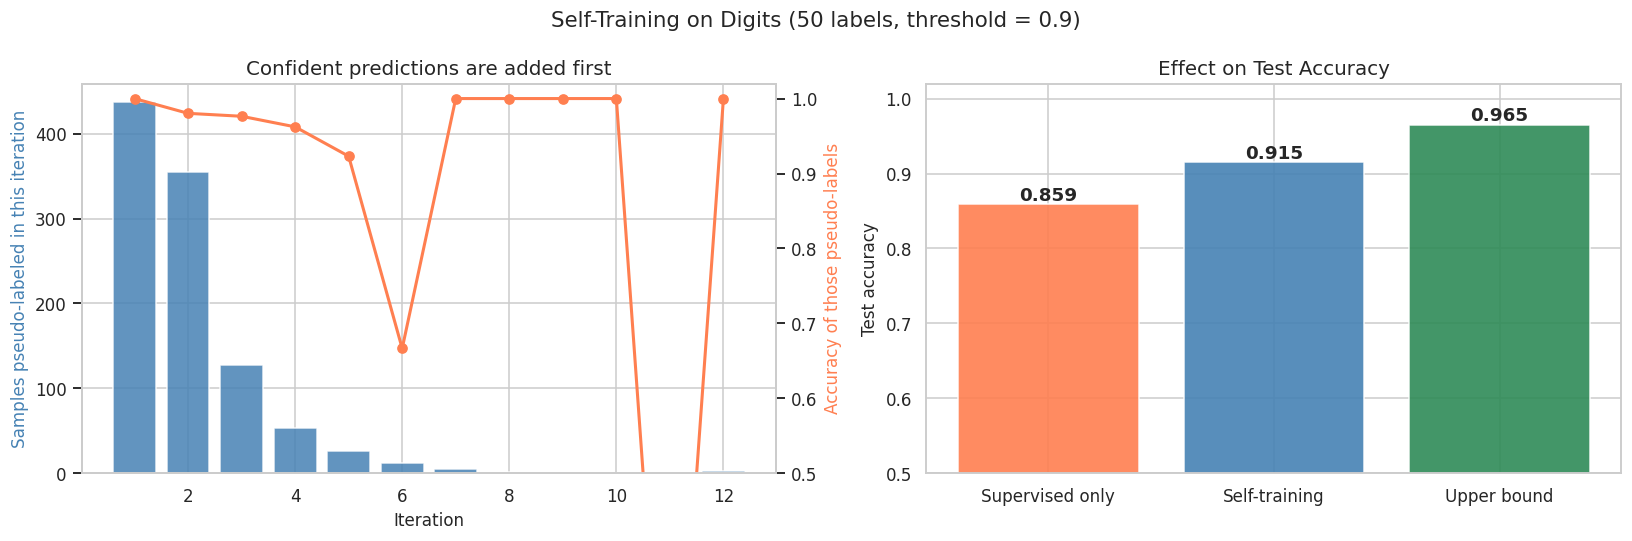

Iterations run: 13   Pseudo-labeled: 1023   Never labeled: 184
Pseudo-label accuracy overall: 0.981


In [ ]:
# ── 3.1  Self-training step by step ──────────────────────────────────
# SelfTrainingClassifier wraps any classifier with predict_proba.
# After fitting, labeled_iter_ tells us in which iteration each sample received its (pseudo-)label:
#   0 = originally labeled,  k = pseudo-labeled in iteration k,  -1 = never labeled.

st = SelfTrainingClassifier(base_clf(), threshold=0.9, max_iter=30)
st.fit(X_train, y_semi)

it = st.labeled_iter_
iters = np.arange(1, st.n_iter_)
new_per_iter = np.array([(it == k).sum() for k in iters])
# We can measure pseudo-label accuracy only because we secretly know the true labels.
pl_acc = np.array([accuracy_score(y_train[it == k], st.transduction_[it == k]) if (it == k).any() else np.nan
                   for k in iters])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Self-Training on Digits (50 labels, threshold = 0.9)", fontsize=14)

axes[0].bar(iters, new_per_iter, color="steelblue", edgecolor="white", alpha=0.85)
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Samples pseudo-labeled in this iteration", color="steelblue")
axes[0].set_title("Confident predictions are added first")
ax2 = axes[0].twinx()
ax2.plot(iters, pl_acc, "o-", color="coral", linewidth=2)
ax2.set_ylabel("Accuracy of those pseudo-labels", color="coral")
ax2.set_ylim(0.5, 1.02)
ax2.grid(False)

st_acc = accuracy_score(y_test, st.predict(X_test))
axes[1].bar(["Supervised only", "Self-training", "Upper bound"], [acc_lower, st_acc, acc_upper],
            color=["coral", "steelblue", "seagreen"], edgecolor="white", alpha=0.9)
for i, v in enumerate([acc_lower, st_acc, acc_upper]):
    axes[1].text(i, v + 0.005, f"{v:.3f}", ha="center", fontweight="bold")
axes[1].set_ylim(0.5, 1.02)
axes[1].set_ylabel("Test accuracy")
axes[1].set_title("Effect on Test Accuracy")

plt.tight_layout()
plt.show()

n_never = int((it == -1).sum())
print(f"Iterations run: {st.n_iter_}   Pseudo-labeled: {int((it > 0).sum())}   Never labeled: {n_never}")
print(f"Pseudo-label accuracy overall: {accuracy_score(y_train[it > 0], st.transduction_[it > 0]):.3f}")

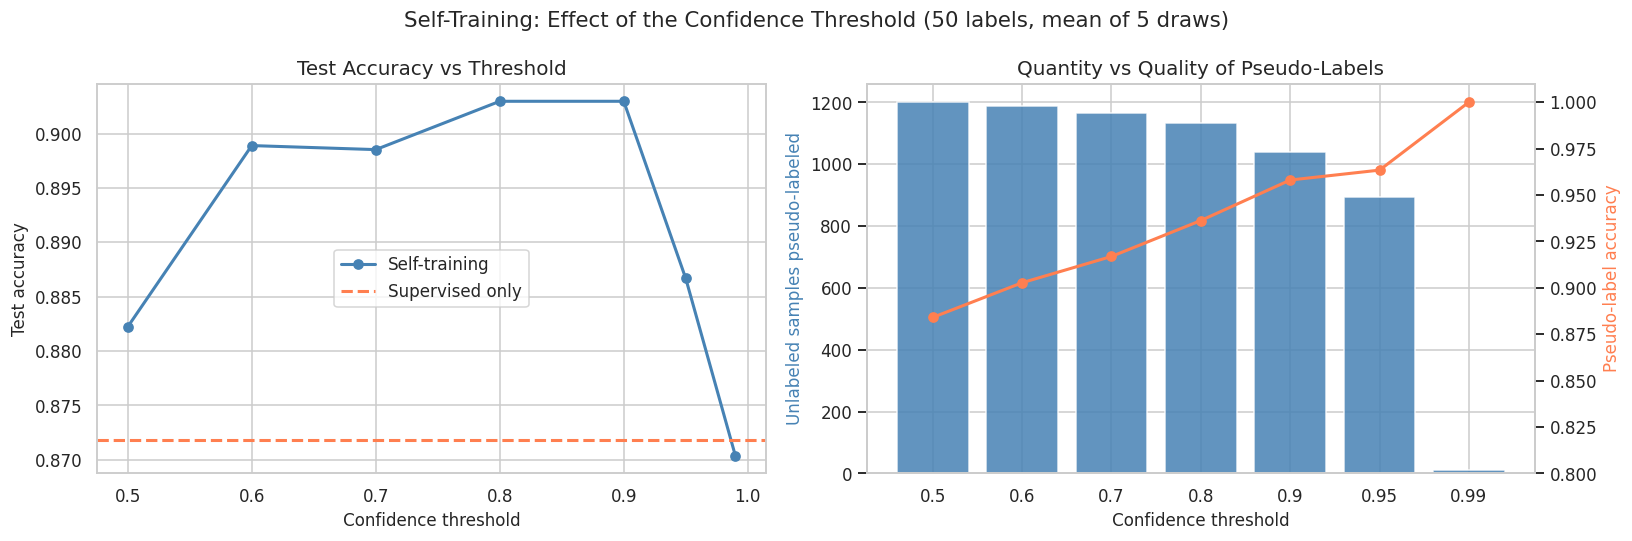

           test_acc  n_pseudo  pseudo_acc  supervised_acc
threshold                                                
0.50          0.882    1200.8       0.884           0.872
0.60          0.899    1186.8       0.903           0.872
0.70          0.899    1166.4       0.917           0.872
0.80          0.903    1134.6       0.936           0.872
0.90          0.903    1040.6       0.958           0.872
0.95          0.887     895.0       0.963           0.872
0.99          0.870      11.0       1.000           0.872

A higher threshold gives cleaner pseudo-labels but fewer of them. At 0.99 almost nothing passes, so
self-training collapses back to the supervised baseline. Pick the threshold with a labeled validation set.


In [ ]:
# ── 3.2  The confidence threshold is the key hyperparameter ──────────
# Sweep the threshold; average over 5 random label draws.

thresholds = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]
rows = []
for thr in thresholds:
    accs, counts, pl_accs, sups = [], [], [], []
    for seed in range(5):
        ys, li = make_semi_labels(y_train, 50, seed)
        m = SelfTrainingClassifier(base_clf(), threshold=thr, max_iter=30).fit(X_train, ys)
        unl = ys == -1
        got = m.labeled_iter_[unl] > 0
        accs.append(accuracy_score(y_test, m.predict(X_test)))
        counts.append(int(got.sum()))
        if got.any():
            pl_accs.append(accuracy_score(y_train[unl][got], m.transduction_[unl][got]))
        sups.append(accuracy_score(y_test, base_clf().fit(X_train[li], y_train[li]).predict(X_test)))
    rows.append({"threshold": thr, "test_acc": np.mean(accs), "n_pseudo": np.mean(counts),
                 "pseudo_acc": np.mean(pl_accs) if pl_accs else np.nan, "supervised_acc": np.mean(sups)})
thr_df = pd.DataFrame(rows).set_index("threshold")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Self-Training: Effect of the Confidence Threshold (50 labels, mean of 5 draws)", fontsize=14)

axes[0].plot(thr_df.index, thr_df["test_acc"], "o-", color="steelblue", linewidth=2, label="Self-training")
axes[0].axhline(thr_df["supervised_acc"].mean(), color="coral", linestyle="--", linewidth=2, label="Supervised only")
axes[0].set_xlabel("Confidence threshold")
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Test Accuracy vs Threshold")
axes[0].legend()

axes[1].bar(thr_df.index.astype(str), thr_df["n_pseudo"], color="steelblue", edgecolor="white", alpha=0.85)
axes[1].set_xlabel("Confidence threshold")
axes[1].set_ylabel("Unlabeled samples pseudo-labeled", color="steelblue")
axes[1].set_title("Quantity vs Quality of Pseudo-Labels")
axb = axes[1].twinx()
axb.plot(thr_df.index.astype(str), thr_df["pseudo_acc"], "o-", color="coral", linewidth=2)
axb.set_ylabel("Pseudo-label accuracy", color="coral")
axb.set_ylim(0.8, 1.01)
axb.grid(False)

plt.tight_layout()
plt.show()

print(thr_df.round(3).to_string())
print("\nA higher threshold gives cleaner pseudo-labels but fewer of them. At 0.99 almost nothing passes, so")
print("self-training collapses back to the supervised baseline. Pick the threshold with a labeled validation set.")

### Exercise 2

Using the **scaled Wine data** and the split from Exercise 1, with **12 labeled** training samples:

1. For thresholds `[0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]` fit a `SelfTrainingClassifier(LogisticRegression(max_iter=3000))` and average over **10 random label draws**.
2. Build a table with: test accuracy, number of pseudo-labeled samples, and pseudo-label accuracy.
3. Plot test accuracy against threshold with the **supervised-only baseline** (same labeled samples) as a dashed line.
4. Which threshold works best? Is the gain over the baseline larger than the draw-to-draw standard deviation?
5. Explain in one sentence why a very high threshold cannot improve on the baseline.

```python
# Your code here
```

```
# Your answer here
```

---
## Part 4: Label Propagation & Label Spreading

These are **graph-based** methods built on the **smoothness assumption**.

1. Build a **similarity graph** connecting each sample to its neighbours (k-nearest neighbours or an RBF kernel).
2. Labeled nodes **push their labels along the edges** to unlabeled neighbours, iteration by iteration, until the label distribution stabilises.

| | Label Propagation | Label Spreading |
|---|---|---|
| **Labeled points** | Clamped: labels never change | Soft: can be revised (controlled by `alpha`) |
| **Noise robustness** | Lower | **Higher** (regularised), so the usual choice |

| Kernel | Graph | Main parameter |
|---|---|---|
| **`knn`** | Each point linked to its $k$ nearest neighbours (sparse, fast) | `n_neighbors` |
| **`rbf`** | All points linked with weight $e^{-\gamma \lVert x - x' \rVert^2}$ (dense) | `gamma` |

> Labels flow through **chains of nearby points**, so these methods can follow curved structures (like two interleaved moons) that a linear classifier cannot.

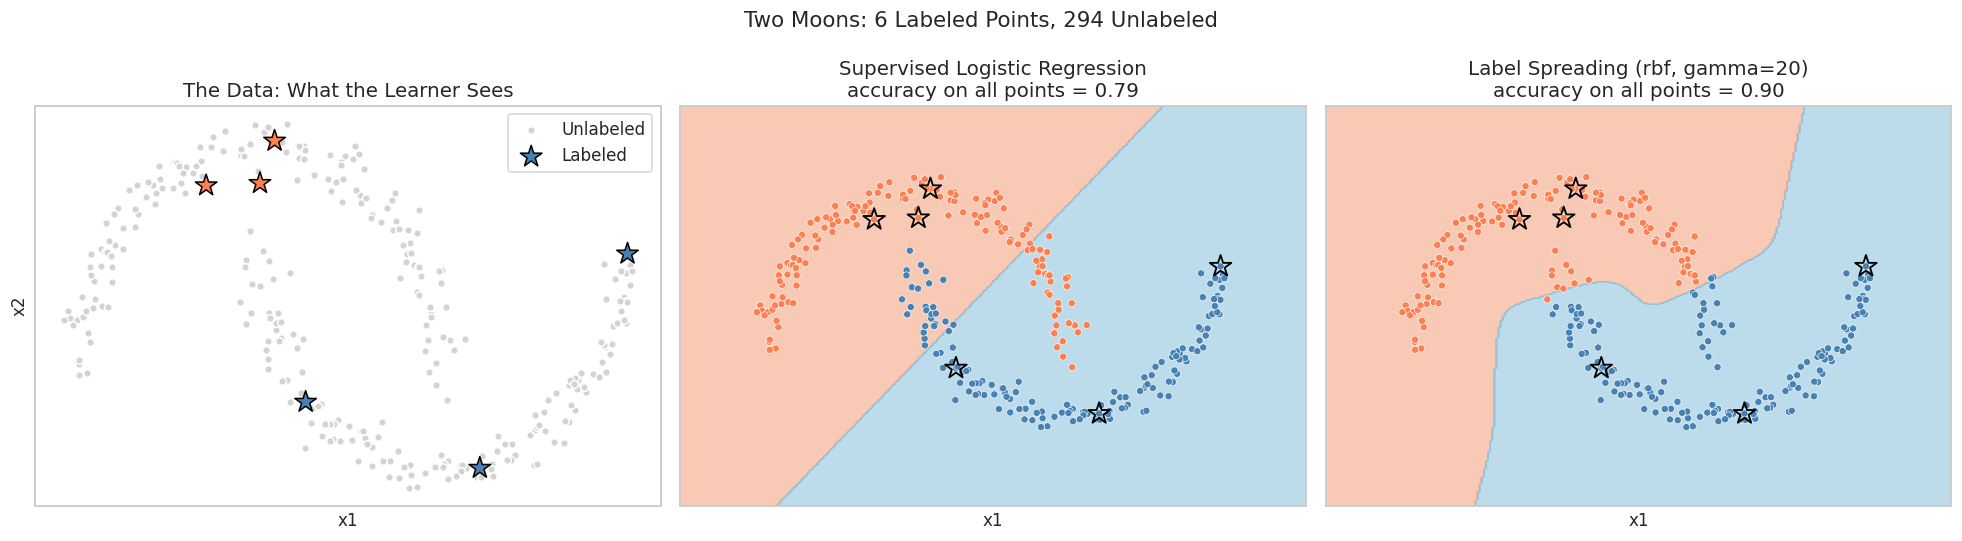

Mean accuracy over 20 label draws:  supervised = 0.792   label spreading = 0.899
Worst draw:                         supervised = 0.707   label spreading = 0.780
The linear model cannot bend; Label Spreading lets labels flow along each moon.


In [ ]:
# ── 4.1  Two moons: a few labels, a curved structure ─────────────────
# 300 points, only 6 labeled (3 per class). Compare a supervised linear model with Label Spreading.

Xm, ym = make_moons(n_samples=300, noise=0.06, random_state=3)
ys_m, lab_m = make_semi_labels(ym, n_labeled=6, seed=0)

lr_m = LogisticRegression().fit(Xm[lab_m], ym[lab_m])
ls_m = LabelSpreading(kernel="rbf", gamma=20, max_iter=200).fit(Xm, ys_m)

xx, yy = np.meshgrid(np.linspace(-1.6, 2.6, 300), np.linspace(-1.1, 1.6, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
bg = ListedColormap(["#f4a582", "#92c5de"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Two Moons: 6 Labeled Points, 294 Unlabeled", fontsize=14)

# (a) the setup
unl = ys_m == -1
axes[0].scatter(Xm[unl, 0], Xm[unl, 1], c="lightgrey", s=25, edgecolors="white", label="Unlabeled")
axes[0].scatter(Xm[lab_m, 0], Xm[lab_m, 1], c=ym[lab_m], cmap=ListedColormap(["coral", "steelblue"]),
                s=220, marker="*", edgecolors="black", linewidth=1, label="Labeled")
axes[0].set_title("The Data: What the Learner Sees")
axes[0].legend(loc="upper right")

# (b) supervised
axes[1].contourf(xx, yy, lr_m.predict(grid).reshape(xx.shape), cmap=bg, alpha=0.6)
axes[1].scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap=ListedColormap(["coral", "steelblue"]), s=22, edgecolors="white", linewidth=0.4)
axes[1].scatter(Xm[lab_m, 0], Xm[lab_m, 1], c="none", s=220, marker="*", edgecolors="black", linewidth=1.2)
axes[1].set_title(f"Supervised Logistic Regression\naccuracy on all points = {lr_m.score(Xm, ym):.2f}")

# (c) label spreading
axes[2].contourf(xx, yy, ls_m.predict(grid).reshape(xx.shape), cmap=bg, alpha=0.6)
axes[2].scatter(Xm[:, 0], Xm[:, 1], c=ls_m.transduction_, cmap=ListedColormap(["coral", "steelblue"]), s=22, edgecolors="white", linewidth=0.4)
axes[2].scatter(Xm[lab_m, 0], Xm[lab_m, 1], c="none", s=220, marker="*", edgecolors="black", linewidth=1.2)
axes[2].set_title(f"Label Spreading (rbf, gamma=20)\naccuracy on all points = {accuracy_score(ym, ls_m.transduction_):.2f}")

for ax in axes:
    ax.set_xlabel("x1"); ax.set_xticks([]); ax.set_yticks([])
axes[0].set_ylabel("x2")

plt.tight_layout()
plt.show()

# One draw can be lucky or unlucky, so check the average over 20 random label draws.
sup_all, ls_all = [], []
for seed in range(20):
    ys_, li_ = make_semi_labels(ym, 6, seed)
    sup_all.append(LogisticRegression().fit(Xm[li_], ym[li_]).score(Xm, ym))
    ls_all.append(accuracy_score(ym, LabelSpreading(kernel="rbf", gamma=20, max_iter=200).fit(Xm, ys_).transduction_))
print(f"Mean accuracy over 20 label draws:  supervised = {np.mean(sup_all):.3f}   label spreading = {np.mean(ls_all):.3f}")
print(f"Worst draw:                         supervised = {min(sup_all):.3f}   label spreading = {min(ls_all):.3f}")
print("The linear model cannot bend; Label Spreading lets labels flow along each moon.")

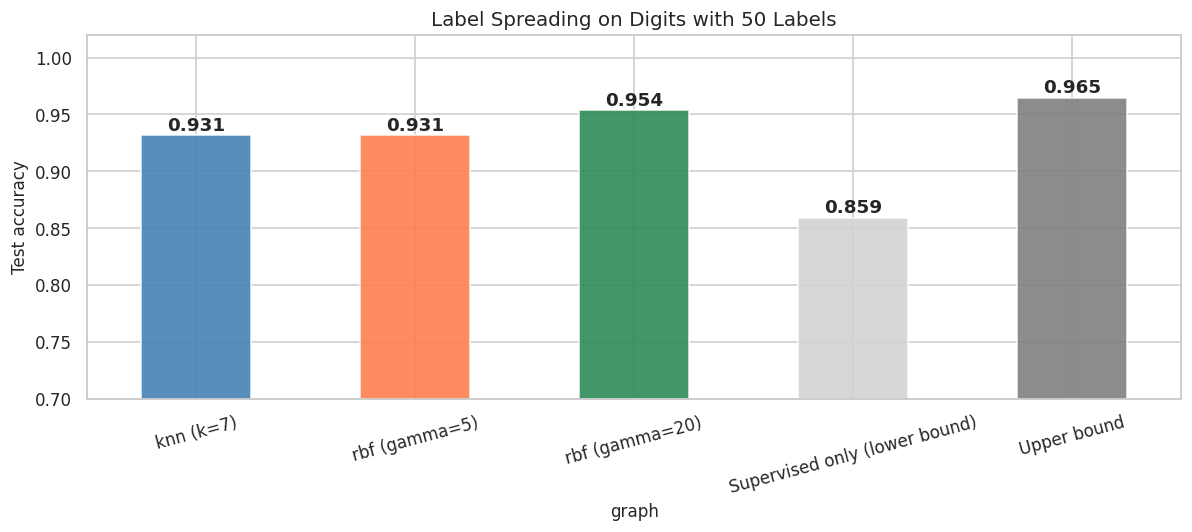

                               transductive_acc  inductive_test_acc
graph                                                              
knn (k=7)                                 0.919               0.931
rbf (gamma=5)                             0.935               0.931
rbf (gamma=20)                            0.961               0.954
Supervised only (lower bound)               NaN               0.859
Upper bound                                 NaN               0.965

With the same 50 labels, spreading labels over the graph beats the supervised model trained on them alone.


In [ ]:
# ── 4.2  Label Spreading on digits: knn vs rbf graph ─────────────────
# Transductive accuracy: on the unlabeled TRAIN points the algorithm labeled for us.
# Inductive accuracy:    on the held-out TEST points (predict() extends the graph to new samples).

configs = {
    "knn (k=7)":      dict(kernel="knn", n_neighbors=7),
    "rbf (gamma=5)":  dict(kernel="rbf", gamma=5),
    "rbf (gamma=20)": dict(kernel="rbf", gamma=20),
}

rows = []
fitted = {}
for name, kw in configs.items():
    m = LabelSpreading(max_iter=200, **kw).fit(X_train, y_semi)
    fitted[name] = m
    rows.append({"graph": name,
                 "transductive_acc": accuracy_score(y_train[unl_idx], m.transduction_[unl_idx]),
                 "inductive_test_acc": accuracy_score(y_test, m.predict(X_test))})
ls_df = pd.DataFrame(rows).set_index("graph")
ls_df.loc["Supervised only (lower bound)"] = [np.nan, acc_lower]
ls_df.loc["Upper bound"] = [np.nan, acc_upper]

fig, ax = plt.subplots(figsize=(11, 5))
ls_df["inductive_test_acc"].plot(kind="bar", ax=ax, edgecolor="white", alpha=0.9,
                                 color=["steelblue", "coral", "seagreen", "lightgrey", "grey"])
for i, v in enumerate(ls_df["inductive_test_acc"]):
    ax.text(i, v + 0.004, f"{v:.3f}", ha="center", fontweight="bold")
ax.set_ylim(0.7, 1.02)
ax.set_ylabel("Test accuracy")
ax.set_title("Label Spreading on Digits with 50 Labels")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

print(ls_df.round(3).to_string())
ls_knn = fitted["knn (k=7)"]       # keep for later cells
print("\nWith the same 50 labels, spreading labels over the graph beats the supervised model trained on them alone.")

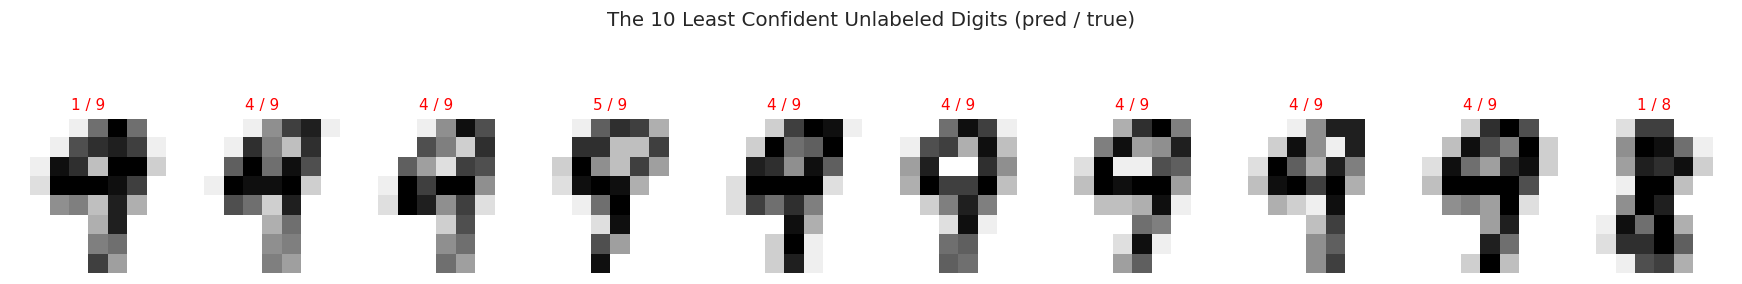

Accuracy on confident unlabeled samples (max prob > 0.9): 0.963  (n = 1092)
Accuracy on unsure unlabeled samples   (max prob <= 0.9): 0.496  (n = 115)
Confidence is informative. This is the basis of active learning: ask a human to label the unsure ones.


In [ ]:
# ── 4.3  Where is Label Spreading unsure? ────────────────────────────
# label_distributions_ holds the probability of each class for every training sample.
# Low maximum probability = the graph could not decide, so these samples deserve a human annotator.

conf = ls_knn.label_distributions_.max(axis=1)
unsure = unl_idx[np.argsort(conf[unl_idx])[:10]]

fig, axes = plt.subplots(1, 10, figsize=(16, 2.6))
fig.suptitle("The 10 Least Confident Unlabeled Digits (pred / true)", fontsize=13, y=1.08)
for ax, i in zip(axes, unsure):
    ax.imshow(X_train[i].reshape(8, 8), cmap="gray_r")
    pred, true = ls_knn.transduction_[i], y_train[i]
    ax.set_title(f"{pred} / {true}", fontsize=10, color="green" if pred == true else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()

hi = unl_idx[conf[unl_idx] > 0.9]
lo = unl_idx[conf[unl_idx] <= 0.9]
print(f"Accuracy on confident unlabeled samples (max prob > 0.9): {accuracy_score(y_train[hi], ls_knn.transduction_[hi]):.3f}  (n = {len(hi)})")
print(f"Accuracy on unsure unlabeled samples   (max prob <= 0.9): {accuracy_score(y_train[lo], ls_knn.transduction_[lo]):.3f}  (n = {len(lo)})")
print("Confidence is informative. This is the basis of active learning: ask a human to label the unsure ones.")

### Exercise 3

Using the **scaled Wine data**, the split from Exercise 1, and **12 labeled** training samples (`make_semi_labels(y_train, 12, seed=0)`):

1. Fit `LabelSpreading` with `kernel="knn"` for `n_neighbors` in `[3, 5, 7, 10]` and with `kernel="rbf"` for `gamma` in `[0.05, 0.1, 0.5, 1]`.
2. For each configuration report the **transductive accuracy** (on the unlabeled training samples) and the **inductive accuracy** (on the test set).
3. Compare against the supervised-only baseline trained on the same 12 labeled samples.
4. Which configuration works best, and how sensitive is Label Spreading to its graph parameters?
5. Why does the `rbf` kernel with a large `gamma` behave like a very local graph?

```python
# Your code here
```

```
# Your answer here
```

---
## Part 5: Cluster-then-Label

The **cluster assumption** says points in the same cluster share a label. So:

1. **Cluster** all training samples (labeled and unlabeled) with K-Means, using **more clusters than classes**.
2. Give each cluster the **majority label** of its labeled members.
3. Clusters with **no labeled member** borrow the label of the nearest labeled cluster.
4. Predict new points by finding their cluster.

| Choice of $k$ | Effect |
|---|---|
| **Too small** | Clusters mix several classes: labels are wrong inside each cluster |
| **Too large** | Most clusters contain no labeled point and must borrow a label from the nearest labeled cluster, so the method drifts toward a nearest-neighbour rule |

> Clustering is **unsupervised**, so this method can use the structure of all samples even when labels are extremely scarce. It fails when clusters do not align with classes (see Part 7).

In [ ]:
# ── 5.1  Implementing cluster-then-label ─────────────────────────────

def cluster_then_label(X_tr, y_semi, X_te, k, seed=0):
    """Return (predicted labels for X_te, labels assigned to every training sample)."""
    km = KMeans(n_clusters=k, n_init=5, random_state=seed).fit(X_tr)
    labeled = y_semi != -1

    cluster_label = np.full(k, -1)
    for c in range(k):                                    # majority vote of labeled members
        members = (km.labels_ == c) & labeled
        if members.any():
            cluster_label[c] = np.bincount(y_semi[members]).argmax()

    known = np.where(cluster_label != -1)[0]              # clusters without labels borrow from the nearest
    for c in np.where(cluster_label == -1)[0]:            # cluster that has one
        d = np.linalg.norm(km.cluster_centers_[known] - km.cluster_centers_[c], axis=1)
        cluster_label[c] = cluster_label[known[d.argmin()]]

    return cluster_label[km.predict(X_te)], cluster_label[km.labels_]

pred_c2l, train_assigned = cluster_then_label(X_train, y_semi, X_test, k=50, seed=0)
print(f"Cluster-then-label (k=50, 50 labels): test accuracy = {accuracy_score(y_test, pred_c2l):.3f}")
print(f"Supervised only on the same labels:   test accuracy = {acc_lower:.3f}")

Cluster-then-label (k=50, 50 labels): test accuracy = 0.919
Supervised only on the same labels:   test accuracy = 0.859


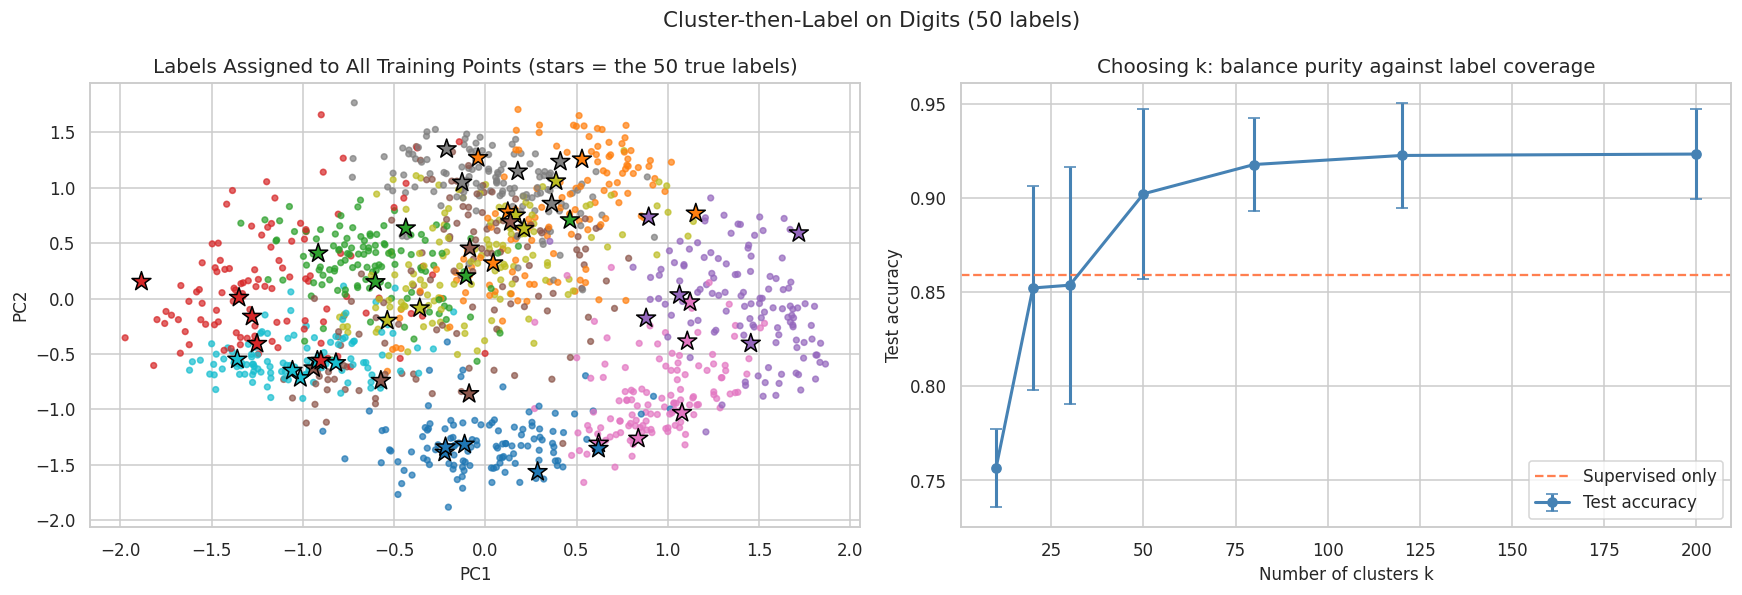

     test_acc    std  clusters_without_label
k                                           
10      0.757  0.021                     0.0
20      0.852  0.054                     1.0
30      0.854  0.063                     4.2
50      0.902  0.045                    16.8
80      0.918  0.025                    42.0
120     0.923  0.028                    78.4
200     0.923  0.024                   155.2

Highest accuracy 0.923; the smallest k within 0.01 of it is k = 80.
Accuracy rises as clusters get purer, then plateaus. Prefer the smallest k on the plateau.


In [ ]:
# ── 5.2  Visualise it, and choose k ──────────────────────────────────

pca2 = PCA(n_components=2, random_state=42).fit(X_train)
P = pca2.transform(X_train)

ks = [10, 20, 30, 50, 80, 120, 200]
k_res = []
for k in ks:
    accs, empty = [], []
    for seed in range(5):
        ys, li = make_semi_labels(y_train, 50, seed)
        p, _ = cluster_then_label(X_train, ys, X_test, k, seed)
        accs.append(accuracy_score(y_test, p))
        km = KMeans(n_clusters=k, n_init=5, random_state=seed).fit(X_train)
        empty.append(k - len(np.unique(km.labels_[li])))
    k_res.append({"k": k, "test_acc": np.mean(accs), "std": np.std(accs), "clusters_without_label": np.mean(empty)})
k_df = pd.DataFrame(k_res).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle("Cluster-then-Label on Digits (50 labels)", fontsize=14)

axes[0].scatter(P[:, 0], P[:, 1], c=train_assigned, cmap="tab10", s=14, alpha=0.7)
axes[0].scatter(P[lab_idx, 0], P[lab_idx, 1], c=y_train[lab_idx], cmap="tab10", s=170, marker="*",
                edgecolors="black", linewidth=1)
axes[0].set_title("Labels Assigned to All Training Points (stars = the 50 true labels)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")

axes[1].errorbar(k_df.index, k_df["test_acc"], yerr=k_df["std"], fmt="o-", color="steelblue",
                 linewidth=2, capsize=4, label="Test accuracy")
axes[1].axhline(acc_lower, color="coral", linestyle="--", linewidth=1.5, label="Supervised only")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Test accuracy")
axes[1].set_title("Choosing k: balance purity against label coverage")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

print(k_df.round(3).to_string())
best_acc = k_df["test_acc"].max()
k_plateau = int(k_df.index[(k_df["test_acc"] >= best_acc - 0.01)].min())
print(f"\nHighest accuracy {best_acc:.3f}; the smallest k within 0.01 of it is k = {k_plateau}.")
print("Accuracy rises as clusters get purer, then plateaus. Prefer the smallest k on the plateau.")

---
## Part 6: Head-to-Head: How Many Labels Do You Need?

The decisive experiment: for each labeling budget, compare all four methods using **the same labeled samples**, averaged over several random draws.

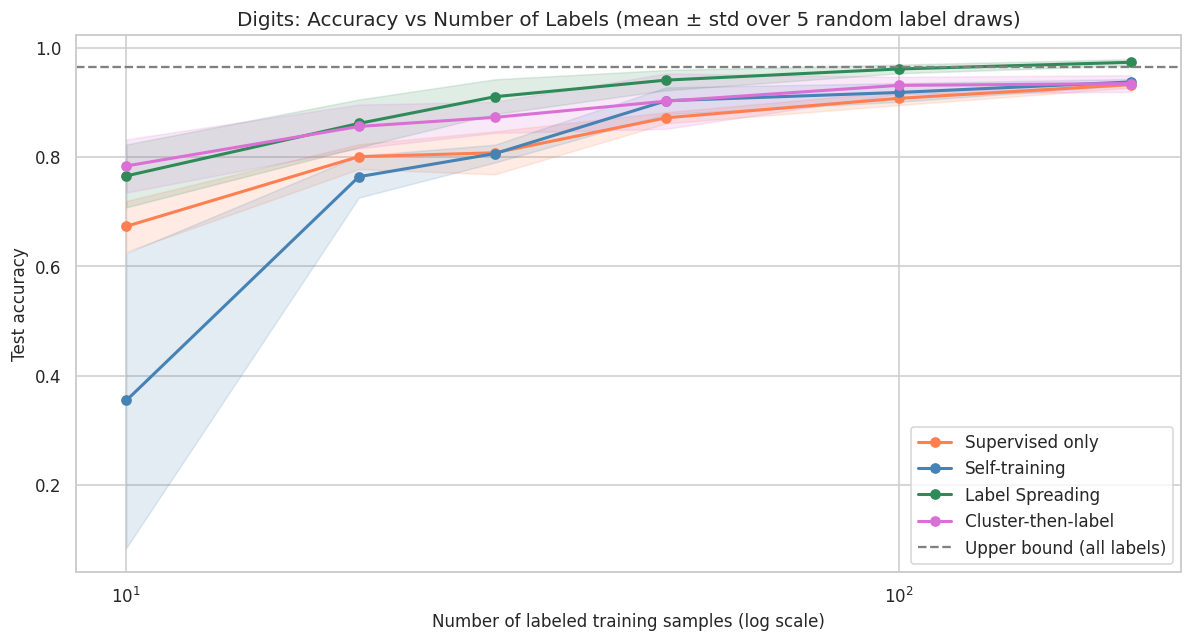

method     Supervised only  Self-training  Label Spreading  Cluster-then-label
n_labeled                                                                     
10                   0.673          0.355            0.766               0.784
20                   0.801          0.764            0.861               0.856
30                   0.808          0.806            0.910               0.873
50                   0.872          0.903            0.941               0.902
100                  0.907          0.918            0.961               0.931
200                  0.933          0.937            0.973               0.934

Gain over supervised-only at 50 labels (accuracy points):
method
Self-training         0.031
Label Spreading       0.069
Cluster-then-label    0.030

Graph and cluster methods gain the most when labels are scarcest, and every gain shrinks as labels become plentiful.
Self-training is the exception: at 10 labels it scores 0.355 vs 0.673 supervised-only.
A model train

In [ ]:
# ── 6.1  Learning curves for all four methods ────────────────────────

def run_methods(Xtr, ytr, Xte, yte, n_labeled, seed, C=10, n_neighbors=7, k=50, threshold=0.9):
    """Train all four methods on the same labeled subset and return test accuracies."""
    ys, li = make_semi_labels(ytr, n_labeled, seed)
    out = {}
    out["Supervised only"] = accuracy_score(
        yte, LogisticRegression(C=C, max_iter=3000).fit(Xtr[li], ytr[li]).predict(Xte))
    st = SelfTrainingClassifier(LogisticRegression(C=C, max_iter=3000), threshold=threshold, max_iter=30).fit(Xtr, ys)
    out["Self-training"] = accuracy_score(yte, st.predict(Xte))
    ls = LabelSpreading(kernel="knn", n_neighbors=n_neighbors, max_iter=100).fit(Xtr, ys)
    out["Label Spreading"] = accuracy_score(yte, ls.predict(Xte))
    pred, _ = cluster_then_label(Xtr, ys, Xte, k, seed)
    out["Cluster-then-label"] = accuracy_score(yte, pred)
    return out

n_grid = [10, 20, 30, 50, 100, 200]
records = []
for n in n_grid:
    for seed in range(5):
        for method, acc in run_methods(X_train, y_train, X_test, y_test, n, seed).items():
            records.append({"n_labeled": n, "seed": seed, "method": method, "acc": acc})
curve_df = pd.DataFrame(records)
summ = curve_df.groupby(["method", "n_labeled"])["acc"].agg(["mean", "std"]).reset_index()

fig, ax = plt.subplots(figsize=(11, 6))
colors = {"Supervised only": "coral", "Self-training": "steelblue",
          "Label Spreading": "seagreen", "Cluster-then-label": "orchid"}
for method, color in colors.items():
    d = summ[summ["method"] == method]
    ax.plot(d["n_labeled"], d["mean"], "o-", color=color, linewidth=2, label=method)
    ax.fill_between(d["n_labeled"], d["mean"] - d["std"], d["mean"] + d["std"], color=color, alpha=0.15)
ax.axhline(acc_upper, color="grey", linestyle="--", linewidth=1.5, label="Upper bound (all labels)")
ax.set_xscale("log")
ax.set_xlabel("Number of labeled training samples (log scale)")
ax.set_ylabel("Test accuracy")
ax.set_title("Digits: Accuracy vs Number of Labels (mean ± std over 5 random label draws)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

table = summ.pivot(index="n_labeled", columns="method", values="mean")[list(colors)]
print(table.round(3).to_string())
gain50 = table.loc[50].drop("Supervised only") - table.loc[50, "Supervised only"]
print("\nGain over supervised-only at 50 labels (accuracy points):")
print(gain50.round(3).to_string())
print("\nGraph and cluster methods gain the most when labels are scarcest, and every gain shrinks as labels become plentiful.")
n10 = table.loc[10]
if n10["Self-training"] < n10["Supervised only"]:
    print(f"Self-training is the exception: at 10 labels it scores {n10['Self-training']:.3f} vs {n10['Supervised only']:.3f} supervised-only.")
    print("A model trained on 10 samples is wrong too often, so it feeds its own mistakes back as pseudo-labels (confirmation bias).")

### Exercise 4

Using the **scaled Wine data** and the split from Exercise 1:

1. Reuse `run_methods` with `C=1, n_neighbors=5, k=9` for `n_labeled` in `[6, 12, 24, 48]`, averaging over **10 random draws**.
2. Plot the four learning curves with the upper bound as a dashed line.
3. Print a table of mean accuracies.
4. At which label budgets (if any) did unlabeled data **help**? Did any method **hurt**?
5. Wine has only 124 training samples in 13 dimensions. Give one reason why graph-based or clustering-based methods may struggle here compared with digits.

```python
# Your code here
```

```
# Your answer here
```

---
## Part 7: When Semi-Supervised Learning Fails

Unlabeled data can **hurt**. The methods above all assume that structure in the features aligns with the labels. When it does not, they propagate **confident mistakes**.

The next experiment builds a dataset where the **cluster assumption is violated**: the data form two clear clusters (left and right), but the class is decided by a **horizontal** boundary that cuts straight through both clusters.

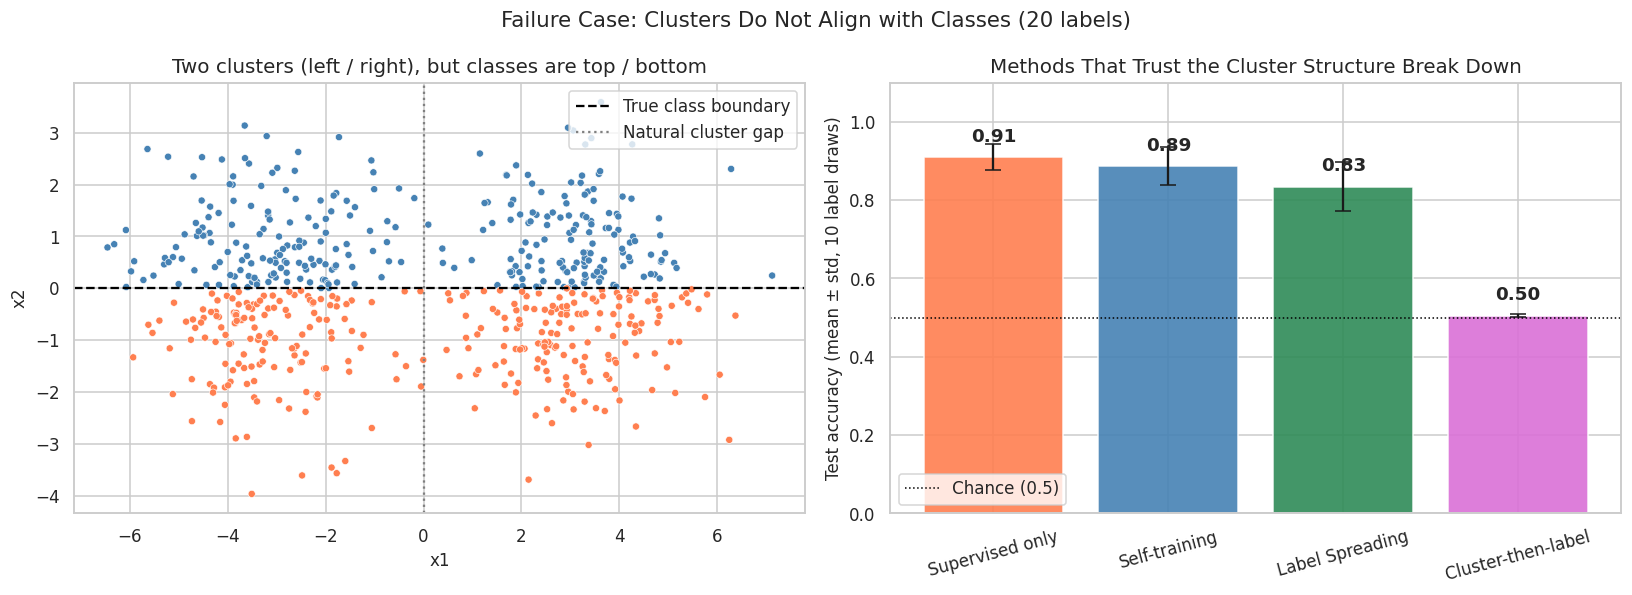

                     mean    std
method                          
Supervised only     0.909  0.033
Self-training       0.886  0.049
Label Spreading     0.834  0.062
Cluster-then-label  0.504  0.004

Cluster-then-label sits at chance: it labels each cluster with one class, but each cluster contains BOTH.
The supervised model, which ignores the unlabeled structure, is the most reliable here.


In [ ]:
# ── 7.1  Violating the cluster assumption ────────────────────────────

Xp, _ = make_blobs(n_samples=600, centers=[(-3, 0), (3, 0)], cluster_std=1.3, random_state=0)
yp = (Xp[:, 1] > 0).astype(int)                 # class = above / below the horizontal axis
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, yp, test_size=0.3, stratify=yp, random_state=0)

pit_records = []
for seed in range(10):
    ys_, li_ = make_semi_labels(yp_tr, 20, seed)
    pit_records.append({"method": "Supervised only",
                        "acc": LogisticRegression().fit(Xp_tr[li_], yp_tr[li_]).score(Xp_te, yp_te)})
    pit_records.append({"method": "Self-training",
                        "acc": SelfTrainingClassifier(LogisticRegression(), threshold=0.9).fit(Xp_tr, ys_).score(Xp_te, yp_te)})
    pit_records.append({"method": "Label Spreading",
                        "acc": LabelSpreading(kernel="knn", n_neighbors=7).fit(Xp_tr, ys_).score(Xp_te, yp_te)})
    pred_, _ = cluster_then_label(Xp_tr, ys_, Xp_te, 2, seed)
    pit_records.append({"method": "Cluster-then-label", "acc": accuracy_score(yp_te, pred_)})
pit_df = pd.DataFrame(pit_records).groupby("method")["acc"].agg(["mean", "std"]).loc[list(colors)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
fig.suptitle("Failure Case: Clusters Do Not Align with Classes (20 labels)", fontsize=14)

axes[0].scatter(Xp[:, 0], Xp[:, 1], c=yp, cmap=ListedColormap(["coral", "steelblue"]), s=22, edgecolors="white", linewidth=0.4)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1.5, label="True class boundary")
axes[0].axvline(0, color="grey", linestyle=":", linewidth=1.5, label="Natural cluster gap")
axes[0].set_title("Two clusters (left / right), but classes are top / bottom")
axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2")
axes[0].legend(loc="upper right")

axes[1].bar(pit_df.index, pit_df["mean"], yerr=pit_df["std"], capsize=5,
            color=[colors[m] for m in pit_df.index], edgecolor="white", alpha=0.9)
for i, v in enumerate(pit_df["mean"]):
    axes[1].text(i, v + 0.04, f"{v:.2f}", ha="center", fontweight="bold")
axes[1].axhline(0.5, color="black", linestyle=":", linewidth=1, label="Chance (0.5)")
axes[1].set_ylim(0, 1.1)
axes[1].set_ylabel("Test accuracy (mean ± std, 10 label draws)")
axes[1].set_title("Methods That Trust the Cluster Structure Break Down")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

print(pit_df.round(3).to_string())
print("\nCluster-then-label sits at chance: it labels each cluster with one class, but each cluster contains BOTH.")
print("The supervised model, which ignores the unlabeled structure, is the most reliable here.")

### A checklist for using semi-supervised learning responsibly

| Rule | Why |
|---|---|
| **Always keep a labeled test set** | Pseudo-labels are not ground truth; only held-out true labels measure real accuracy |
| **Compare with supervised-only on the same labeled samples** | Otherwise you cannot tell whether unlabeled data helped |
| **Check that labeled and unlabeled data come from the same distribution** | Unlabeled data from a different source can mislead the model |
| **Inspect the assumption** (clusters? smooth manifold?) | The method is only as good as its assumption |
| **Tune thresholds and graph parameters on a labeled validation set** | Not on the test set and not on pseudo-labels |
| **Report variability over several random label draws** | With few labels, the choice of which samples are labeled changes results a lot |

---
## Part 8: The Full Semi-Supervised Dashboard: Storytelling

**Storytelling checklist:**
1. **Value:** how much accuracy does unlabeled data buy at each labeling budget?
2. **Mechanism:** how does pseudo-label quality trade against quantity?
3. **Errors:** which classes remain confused after using unlabeled data?
4. **Risk:** when does the approach fail?

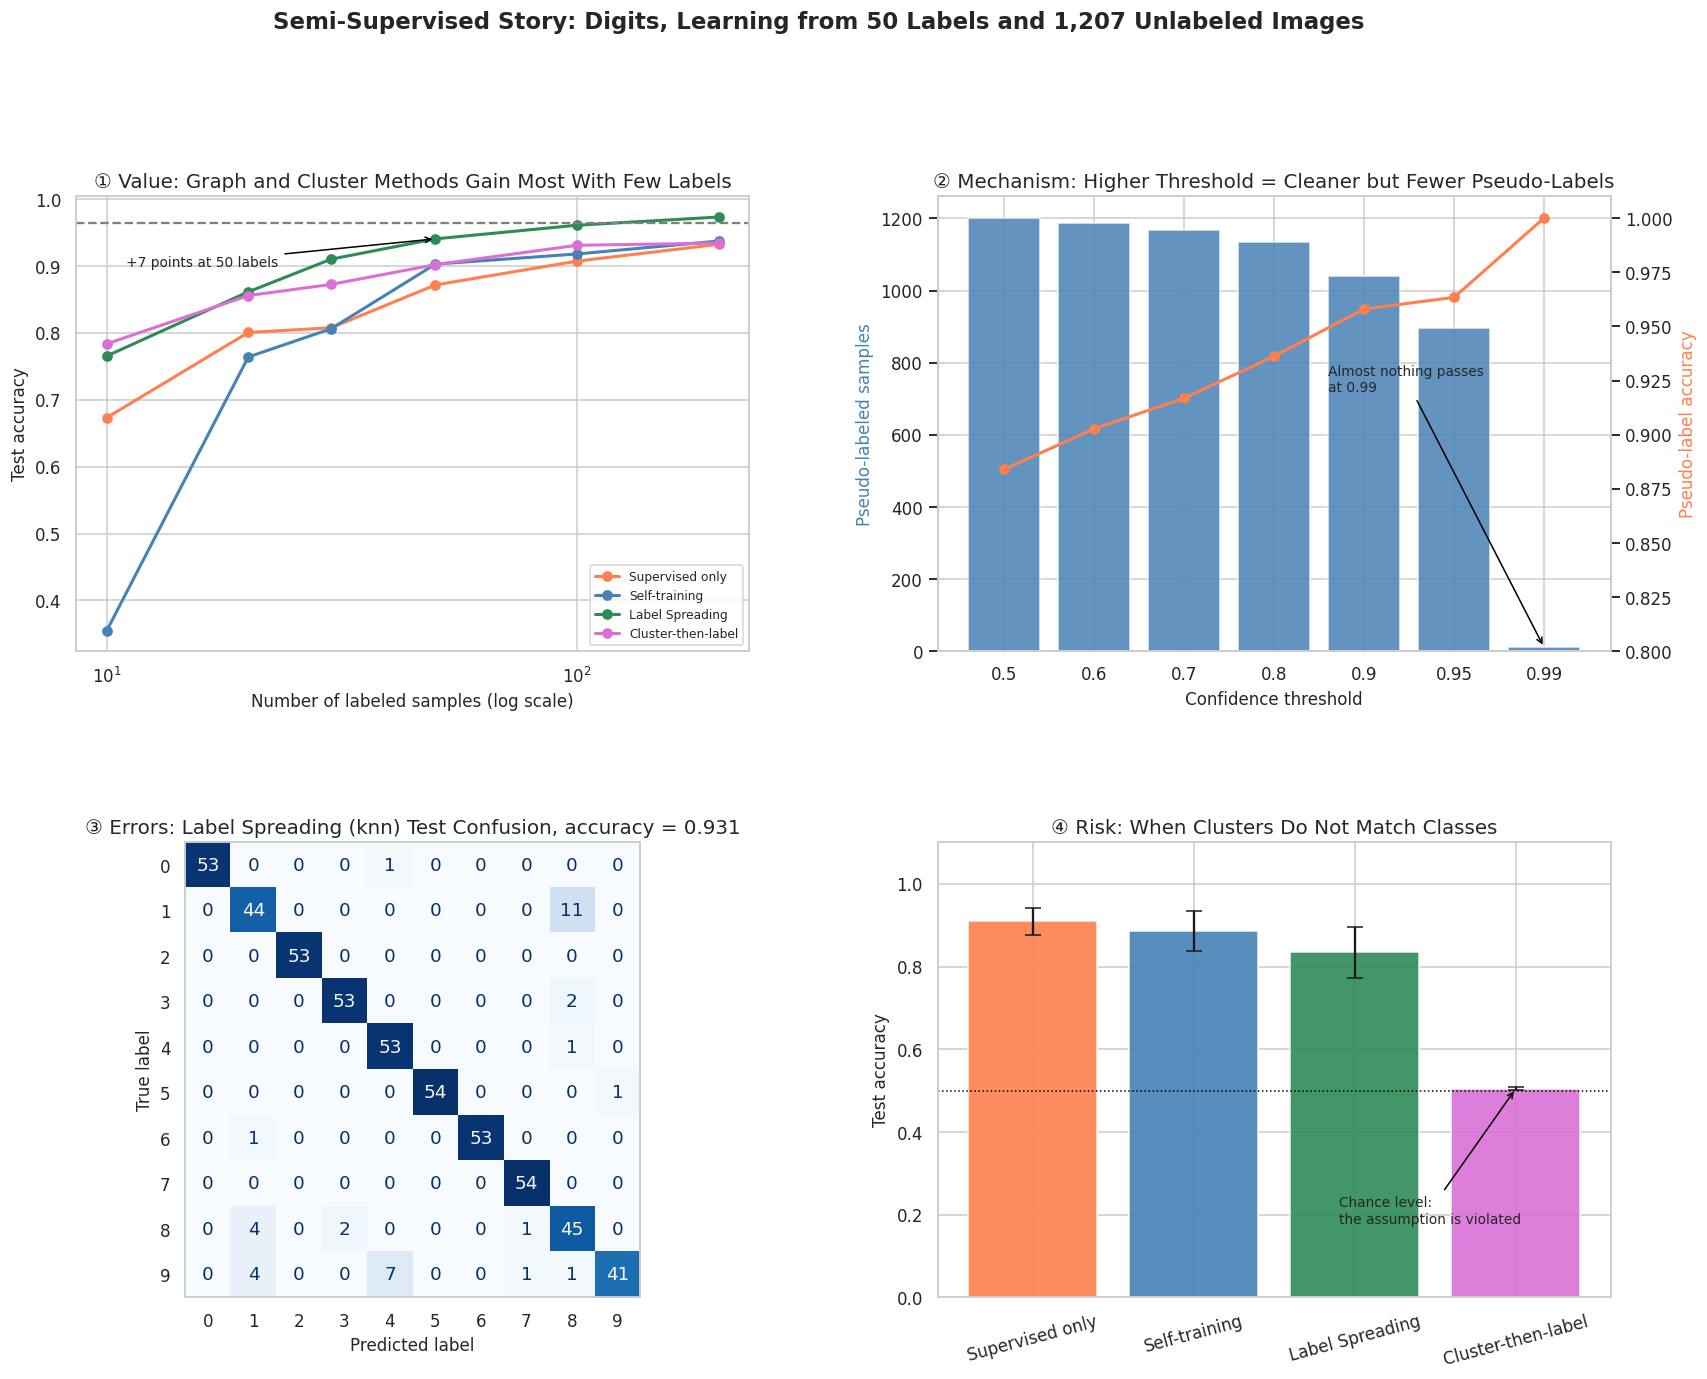

Dashboard saved as semisupervised_dashboard.png


In [ ]:
# ── 8.1  The Semi-Supervised Dashboard ───────────────────────────────

fig = plt.figure(figsize=(18, 13))
fig.suptitle("Semi-Supervised Story: Digits, Learning from 50 Labels and 1,207 Unlabeled Images",
             fontsize=15, fontweight="bold", y=1.01)

gs = gridspec.GridSpec(2, 2, hspace=0.42, wspace=0.28)

# ── Panel 1: learning curves ──────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
for method, color in colors.items():
    d = summ[summ["method"] == method]
    ax1.plot(d["n_labeled"], d["mean"], "o-", color=color, linewidth=2, label=method)
ax1.axhline(acc_upper, color="grey", linestyle="--", linewidth=1.5)
ax1.set_xscale("log")
ax1.set_xlabel("Number of labeled samples (log scale)")
ax1.set_ylabel("Test accuracy")
ax1.set_title("① Value: Graph and Cluster Methods Gain Most With Few Labels")
ax1.legend(loc="lower right", fontsize=8)
s50 = table.loc[50]
ax1.annotate(f"+{(s50['Label Spreading'] - s50['Supervised only']) * 100:.0f} points at 50 labels",
             xy=(50, s50["Label Spreading"]), xytext=(11, 0.90), fontsize=9,
             arrowprops=dict(arrowstyle="->", color="black"))

# ── Panel 2: pseudo-label quantity vs quality ─────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
ax2.bar(thr_df.index.astype(str), thr_df["n_pseudo"], color="steelblue", edgecolor="white", alpha=0.85)
ax2.set_xlabel("Confidence threshold")
ax2.set_ylabel("Pseudo-labeled samples", color="steelblue")
ax2.set_title("② Mechanism: Higher Threshold = Cleaner but Fewer Pseudo-Labels")
ax2b = ax2.twinx()
ax2b.plot(thr_df.index.astype(str), thr_df["pseudo_acc"], "o-", color="coral", linewidth=2)
ax2b.set_ylabel("Pseudo-label accuracy", color="coral")
ax2b.set_ylim(0.8, 1.01)
ax2b.grid(False)
ax2.annotate("Almost nothing passes\nat 0.99", xy=(6, thr_df["n_pseudo"].iloc[-1]),
             xytext=(3.6, thr_df["n_pseudo"].max() * 0.6), fontsize=9,
             arrowprops=dict(arrowstyle="->", color="black"))

# ── Panel 3: confusion matrix of Label Spreading ──────────────────────
ax3 = fig.add_subplot(gs[1, 0])
ConfusionMatrixDisplay.from_predictions(y_test, ls_knn.predict(X_test), cmap="Blues",
                                        colorbar=False, ax=ax3, values_format="d")
ax3.grid(False)
ax3.set_title(f"③ Errors: Label Spreading (knn) Test Confusion, accuracy = {accuracy_score(y_test, ls_knn.predict(X_test)):.3f}")

# ── Panel 4: the failure case ─────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
ax4.bar(pit_df.index, pit_df["mean"], yerr=pit_df["std"], capsize=5,
        color=[colors[m] for m in pit_df.index], edgecolor="white", alpha=0.9)
ax4.axhline(0.5, color="black", linestyle=":", linewidth=1)
ax4.set_ylim(0, 1.1)
ax4.set_ylabel("Test accuracy")
ax4.set_title("④ Risk: When Clusters Do Not Match Classes")
ax4.tick_params(axis="x", rotation=15)
ax4.annotate("Chance level:\nthe assumption is violated", xy=(3, pit_df["mean"].iloc[-1]),
             xytext=(1.9, 0.18), fontsize=9, arrowprops=dict(arrowstyle="->", color="black"))

plt.tight_layout()
plt.savefig("semisupervised_dashboard.png", dpi=110, bbox_inches="tight")
plt.show()
print("Dashboard saved as semisupervised_dashboard.png")

### Exercise 5: Final Challenge

Using the **scaled Wine data** (13 features, 3 classes) with the split from Exercise 1, build your own **Semi-Supervised Dashboard**.

1. **Panel 1 (Value):** learning curves of all four methods for `n_labeled` in `[6, 12, 24, 48]` (10 draws), with the upper bound dashed.
2. **Panel 2 (Mechanism):** for 12 labels, a bar chart of the number of pseudo-labeled samples per threshold, with pseudo-label accuracy as a line on a twin axis.
3. **Panel 3 (Errors):** 3 × 3 confusion matrix of the best semi-supervised method (or of the supervised baseline if nothing beat it) on the test set.
4. **Panel 4 (Structure):** PCA 2D scatter of the training set. Show unlabeled points in grey and the 12 labeled points as coloured stars.
5. Combine all four panels in a `2×2` `GridSpec` figure with a headline title.
6. Add **at least one annotation** on any panel highlighting the most important insight.
7. Write 3-4 sentences below the dashboard summarising:
   - Did unlabeled data help on this dataset, and by how much?
   - Which method would you use and why?
   - How does the answer change with the number of labels?
   - Would you recommend collecting more labels or more unlabeled data for this problem?

```python
# Your code here
```

```
# Your answer here
```

---
## Summary

| Concept | What it solves | Key tools |
|---|---|---|
| **Scarce labels** | Labelling is expensive, raw data is cheap | Mark unlabeled samples with `-1` |
| **Baselines** | Know what "better" means | Supervised on the same few labels (lower), on all labels (upper) |
| **Self-training** | Let the model label its own confident predictions | `SelfTrainingClassifier`, `threshold` |
| **Label Propagation / Spreading** | Spread labels along a similarity graph | `LabelSpreading`, `kernel="knn"` or `"rbf"` |
| **Cluster-then-label** | Use clusters as label carriers | `KMeans` + majority vote |
| **Learning curve over label budget** | Quantify the value of unlabeled data | Repeat over several random label draws |
| **Pseudo-label quality** | Avoid confirmation bias | Threshold, validation on labeled data |
| **Failure analysis** | Know when the assumptions break | Check cluster / smoothness assumptions |

---
**The semi-supervised decision loop:**
1. Hold out a labeled test set, then hide most training labels  
2. Fit the supervised baselines on the few labels and on all labels  
3. Pick a method that matches your data's structure (graph smoothness, clusters, confident model)  
4. Tune its key parameter (threshold, `n_neighbors` or `gamma`, `k`) on a labeled validation set  
5. Compare with the baseline over several random label draws, never a single one  
6. Check the assumption: if clusters or neighbours do not align with classes, stay supervised (or label more data)